# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [ ]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [ ]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Write your code here to read the data
df = pd.read_csv('/content/drive/MyDrive/foodhub_order.csv')

In [ ]:
# Write your code here to view the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [ ]:
# Write your code here
df.shape

(1898, 9)

#### Observations: The dataset contains 1898 rows and 9 columns.


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [ ]:
# Write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations: The dataset contains 4 integer columns (order_id, customer_id, food_preparation_time, delivery_time), 1 float column (cost_of_the_order), and 4 object (categorical) columns (restaurant_name, cuisine_type, day_of_the_week, rating).


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [ ]:
# Write your code here
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


In [ ]:
# Check unique values before treatment
df['rating'].unique()

array(['Not given', '5', '3', '4'], dtype=object)

#### Observations: Although the dataset does not contain explicit NaN values, the rating column includes entries labeled "Not given" which do not represent valid numeric ratings and therefore behave as implicit missing values. For accurate analysis, these entries should be treated as missing data. An appropriate treatment method is to convert the rating values to a numeric format, replace"Not given" with NaN, and impute the missing values using the median rating (5.0), as the median is robust to outliers and preserves the overall distribution of ratings.

In [ ]:
# Create a new column from original rating column
df['rating_imputed'] = df['rating']

# Replace implicit missing values
df['rating_imputed'] = df['rating_imputed'].replace('Not given', np.nan)

# Convert datatype
df['rating_imputed'] = df['rating_imputed'].astype(float)

# Impute missing values using median
df['rating_imputed'] = df['rating_imputed'].fillna(df['rating_imputed'].median())

In [ ]:
# Check results
df[['rating','rating_imputed']].head()

,rating,rating_imputed
0,Not given,5.0
1,Not given,5.0
2,5,5.0
3,3,3.0
4,4,4.0


In [ ]:
 # Check missing values before and after treatment:
df[['rating','rating_imputed']].isnull().sum()

,0
rating,0
rating_imputed,0


In [ ]:
# Check unique values before treatment
df['rating'].unique()

array(['Not given', '5', '3', '4'], dtype=object)

In [ ]:
# Check unique values after treatment
df['rating_imputed'].unique()

array([5., 3., 4.])

In [ ]:
df[['rating','rating_imputed']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   rating          1898 non-null   object 
 1   rating_imputed  1898 non-null   float64
dtypes: float64(1), object(1)
memory usage: 29.8+ KB


#### Observation: The rating column contained implicit missing values represented as “Not given”. A new column rating_imputed was created to preserve the original data. The implicit missing values were converted to NaN, datatype was changed to float, and missing values were imputed using median imputation.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [ ]:
# Write your code here
df.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time,rating_imputed
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749,4.598525
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637,0.662289
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000,3.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000,4.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000,5.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000,5.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000,5.000000


#### Observations:
From the statistical summary of the dataset, the food preparation time takes:

Minimum: 20 minutes

Average (mean): 27.37 minutes

Maximum: 35 minutes

### **Question 5:** How many orders are not rated? [1 mark]

In [ ]:
# Write the code here
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


#### Observations: In the rating column, 736 orders are shown as "Not given" since they have not been rated. To retain information about unrated orders while handling missing values, the original rating column was preserved and a separate column containing imputed ratings was created. This approach enables accurate comparison between original and treated data and supports analysis of orders where ratings were not initially provided.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

Order ID

In [ ]:
# check unique order ID
df['order_id'].nunique()

1898

Customer ID

In [ ]:
# check unique customer ID
df['customer_id'].nunique()

1200

Restaurant name

In [ ]:
# check unique Restaurant name
df['restaurant_name'].nunique()

178

Cusine type

In [ ]:
# check unique Cusine type
df['cuisine_type'].nunique()

14

<Axes: xlabel='cuisine_type', ylabel='count'>

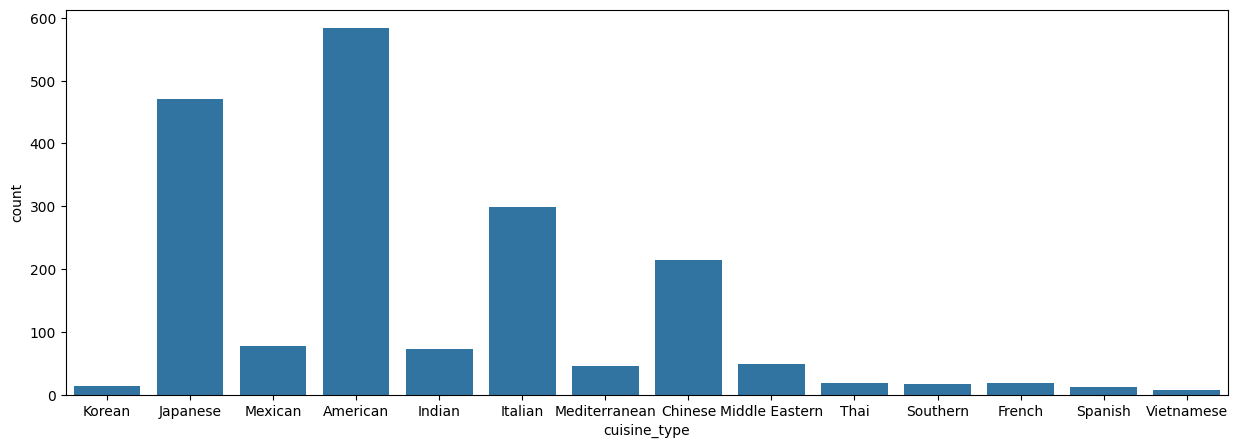

In [ ]:
plt.figure(figsize = (15,5))
sns.countplot(data = df, x = 'cuisine_type') # Create a countplot for cuisine type.

Cost of the order

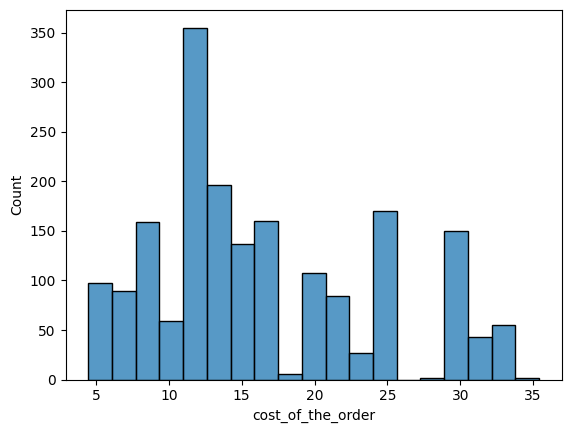

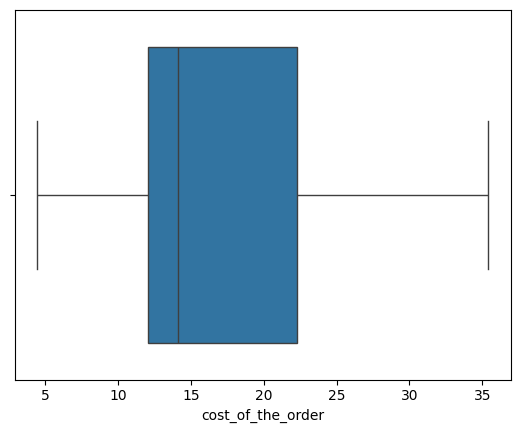

In [ ]:
sns.histplot(data=df,x='cost_of_the_order') # Histogram for the cost of order
plt.show()
sns.boxplot(data=df,x='cost_of_the_order') # Boxplot for the cost of order
plt.show()

Day of the week

In [ ]:
# Check the unique values
df['day_of_the_week'].unique()

array(['Weekend', 'Weekday'], dtype=object)

<Axes: xlabel='day_of_the_week', ylabel='count'>

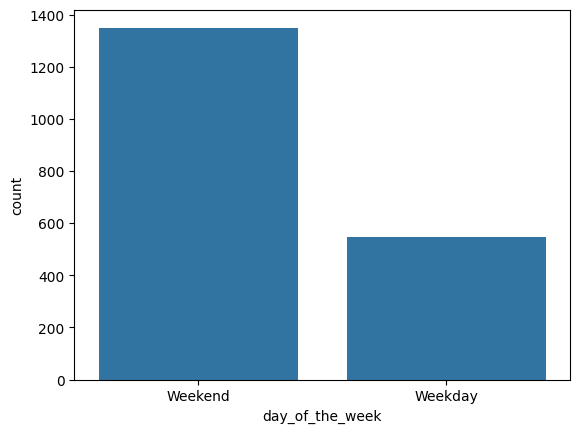

In [ ]:
sns.countplot(data = df, x = 'day_of_the_week') # Create a countplot for day of the week

Rating

In [ ]:
# Check the unique values
df['rating'].unique()

array(['Not given', '5', '3', '4'], dtype=object)

<Axes: xlabel='rating', ylabel='count'>

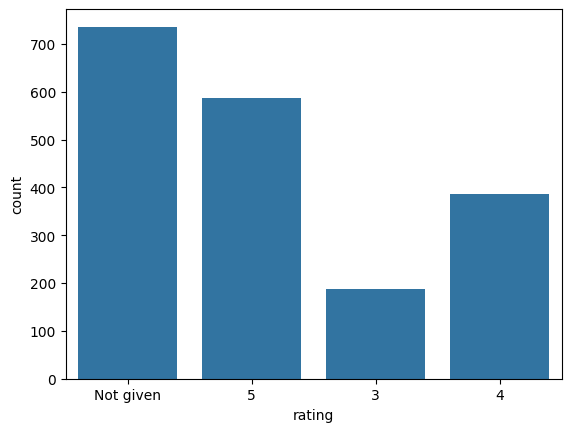

In [ ]:
sns.countplot(data = df, x = 'rating') # Create a countplot for 'rating' column

Food preparation time

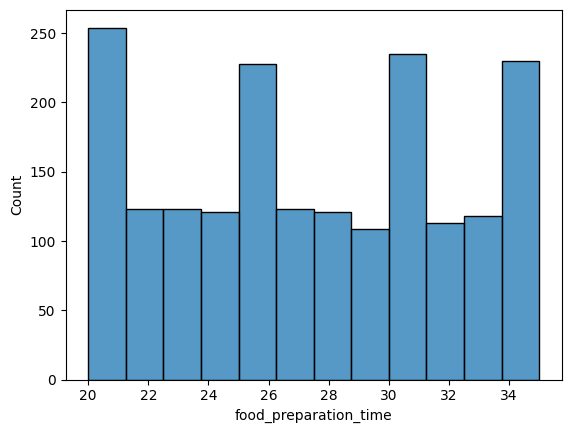

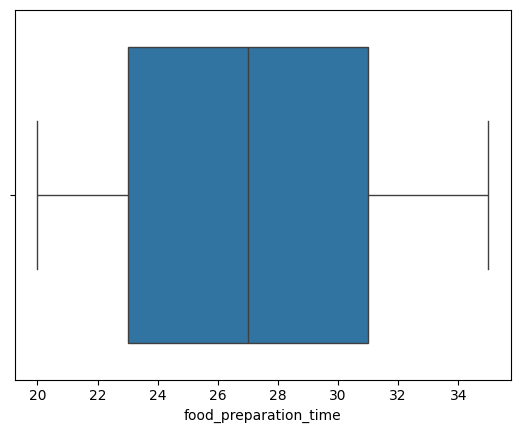

In [ ]:
sns.histplot(data=df,x='food_preparation_time') # Histogram for the food preparation time
plt.show()
sns.boxplot(data=df,x='food_preparation_time') # Boxplot for the food preparation time
plt.show()

Delivery time

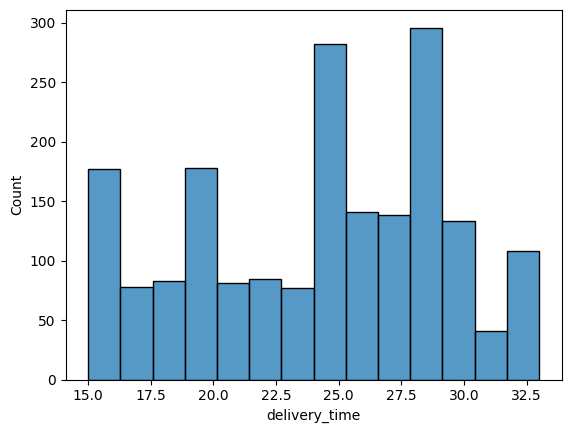

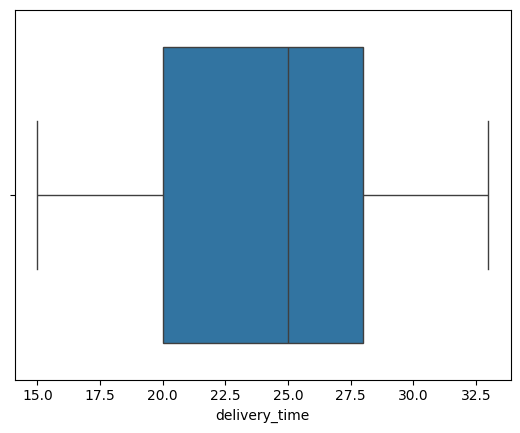

In [ ]:
sns.histplot(data=df,x='delivery_time') # Histogram for the delivery time
plt.show()
sns.boxplot(data=df,x='delivery_time') # Boxplot for the delivery time
plt.show()

#### Observation: The univariate analysis shows that order IDs and customer IDs act as unique identifiers, confirming no duplicate orders. The dataset contains a diverse set of restaurants and cuisine types, although a few cuisines dominate order frequency, indicating strong customer preference patterns. The cost of the order distribution is moderately right-skewed, with most orders concentrated in a mid-price range and a small number of higher-value outliers. Orders are unevenly distributed across the day of the week, with higher demand observed during weekends. The customer ratings distribution is heavily concentrated toward higher ratings, reflecting generally positive customer satisfaction. The food preparation time appears fairly symmetric (approximately normally distributed) with most values clustered around the central range, showing consistent kitchen performance rather than skewness. Similarly, delivery time shows moderate variability with some higher-time outliers indicating occasional delivery delays. Overall, the distributions suggest stable operational performance, high customer satisfaction, and identifiable demand trends across cuisine types and ordering days.

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [ ]:
# Get top 5 restaurants with highest number of orders
df['restaurant_name'].value_counts().head(5)

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations: The top 5 restaurants with the highest number of orders are:

1. Shake Shack - 219 orders
2. The Meatball Shop - 132 orders
3. Blue Ribbon Sushi - 119 orders
4. Blue Ribbon Fried Chicken - 96 orders
5. Parm - 68 orders



### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [ ]:
# Get most popular cuisine on weekends
df_weekend = df[df['day_of_the_week'] == 'Weekend']
df_weekend['cuisine_type'].value_counts()

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Middle Eastern,32
Mediterranean,32
Thai,15


#### Observations: The most popular cuisine on weekends is American, with 415 orders, followed by Japanese (335) and Italian (207).


### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [ ]:
# Get orders that cost above 20 dollars
df_greater_than_20 = df[df['cost_of_the_order']>20]

# Calculate the number of total orders where the cost is above 20 dollars
print('The number of total orders that cost above 20 dollars is:', df_greater_than_20.shape[0])

# Calculate percentage of such orders in the dataset
percentage = (df_greater_than_20.shape[0] / df.shape[0]) * 100

print("Percentage of orders above 20 dollars:", round(percentage, 2), '%')

The number of total orders that cost above 20 dollars is: 555
Percentage of orders above 20 dollars: 29.24 %


#### Observations:
555 orders cost more than 20 dollars.

These orders make up 29.24% of the total dataset.

### **Question 10**: What is the mean order delivery time? [1 mark]

In [ ]:
# Get the mean order delivery time
mean_delvery_time = df['delivery_time'].mean()

print('The mean order delivery time is', round(mean_delvery_time, 2), 'minutes')

The mean order delivery time is 24.16 minutes


#### Observations: The mean order delivery time is 24.16 minutes, indicating that, on average, customers receive their orders in about 24 minutes.


### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [ ]:
# Get the counts of  each customer_id
df['customer_id'].value_counts().head(3)

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations:
Customer ID 52832 placed 13 orders — the highest number of purchases.

Customer ID 47440 placed 10 orders.

Customer ID 83287 placed 9 orders.

These three customers are the most frequent buyers and are ideal candidates for the 20% discount voucher reward.

### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


Cuisine type vs Cost of the order

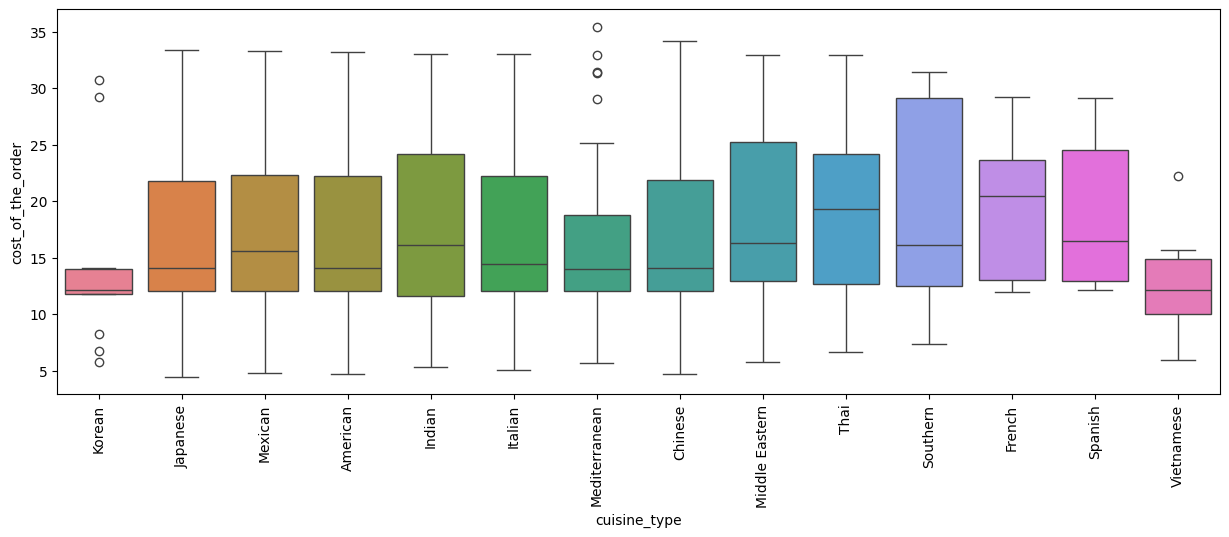

In [ ]:
# Relationship between cuisine type and cost of the order
plt.figure(figsize=(15,5))
sns.boxplot(x = "cuisine_type", y = "cost_of_the_order", data = df, hue = "cuisine_type")
plt.xticks(rotation = 90)
plt.show()

Cuisine type vs Food preparation time


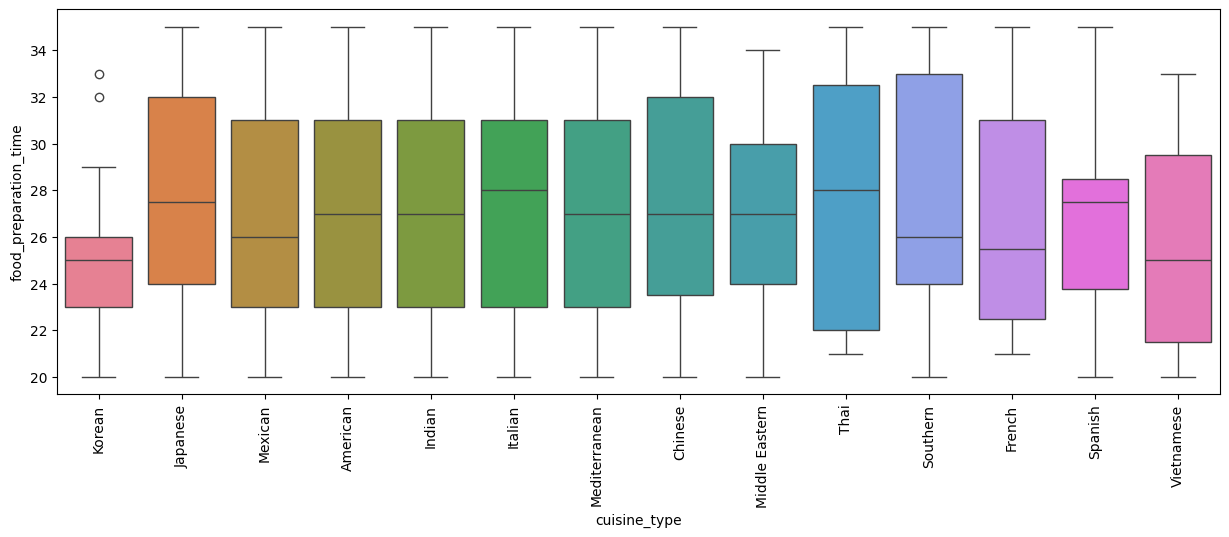

In [ ]:
# Relationship between cuisine type and food preparation time
plt.figure(figsize=(15,5))
sns.boxplot (x = "cuisine_type", y = "food_preparation_time", data = df, hue = "cuisine_type")
plt.xticks(rotation = 90)
plt.show()

Day of the week vs Delivery time

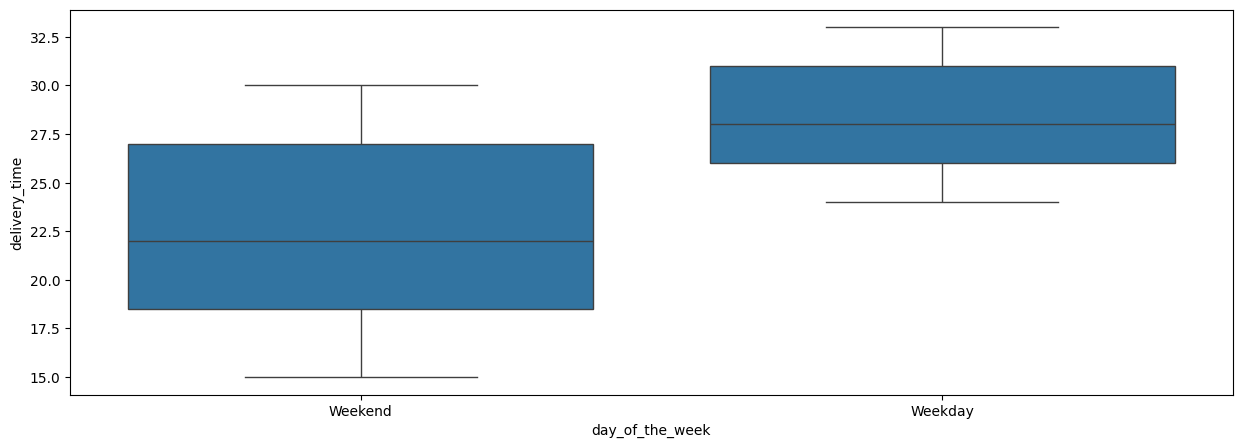

In [ ]:
# Relationship between day of the week and delivery time
plt.figure(figsize=(15,5))
sns.boxplot (x = "day_of_the_week", y = "delivery_time", data = df)
plt.show()

Observations on the revenue generated by the restaurants

In [ ]:
df.groupby(['restaurant_name'])['cost_of_the_order'].sum().sort_values(ascending = False).head(10)

,cost_of_the_order
restaurant_name,
Shake Shack,3579.53
The Meatball Shop,2145.21
Blue Ribbon Sushi,1903.95
Blue Ribbon Fried Chicken,1662.29
Parm,1112.76
RedFarm Broadway,965.13
RedFarm Hudson,921.21
TAO,834.50
Han Dynasty,755.29


Rating vs Delivery time

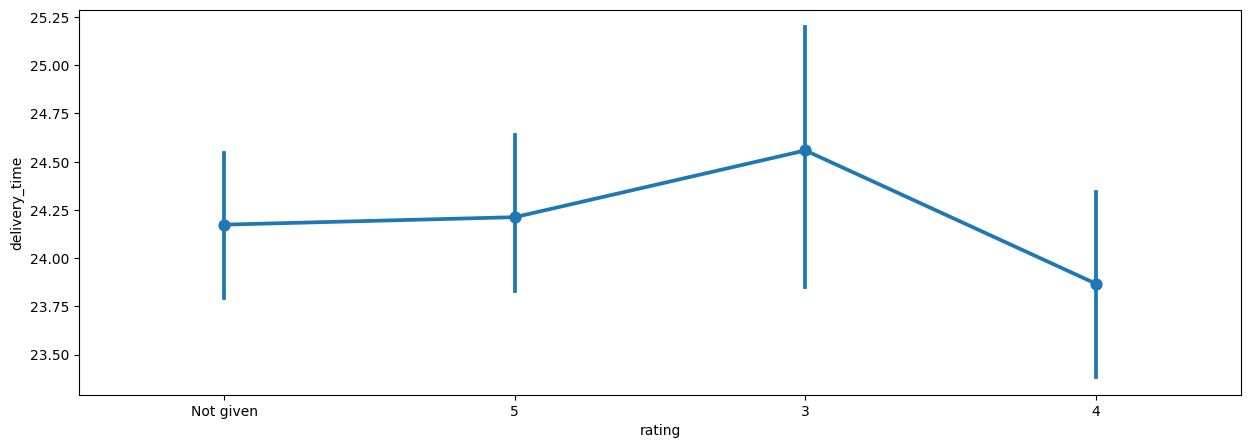

In [ ]:
# Relationship between rating and delivery time
plt.figure(figsize=(15, 5))
sns.pointplot (x = "rating", y = "delivery_time", data = df)
plt.show()

Rating vs Food preparation time

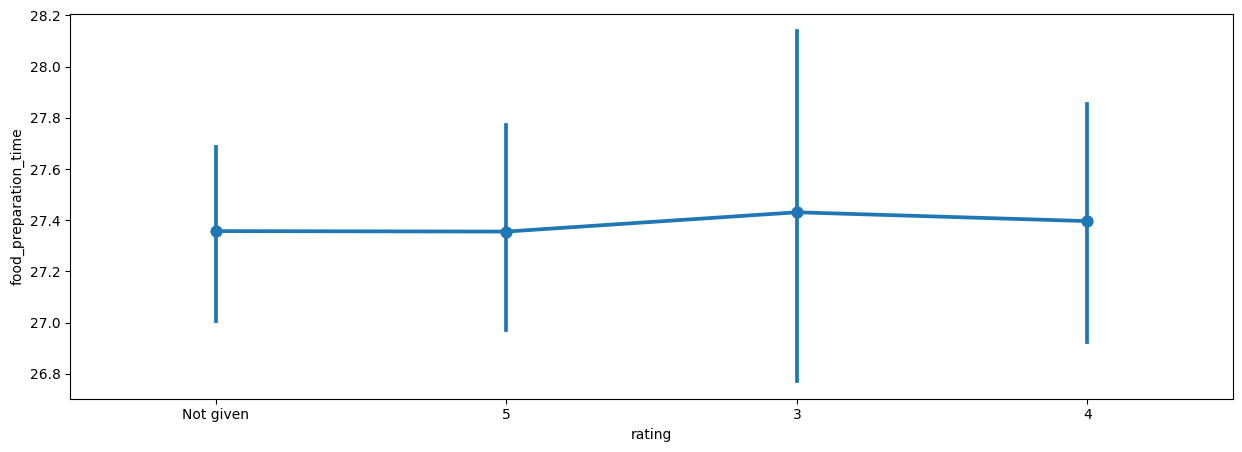

In [ ]:
# Relationship between rating and food preparation time
plt.figure(figsize=(15, 5))
sns.pointplot (x = "rating", y = "food_preparation_time", data = df)
plt.show()

Rating vs Cost of the order

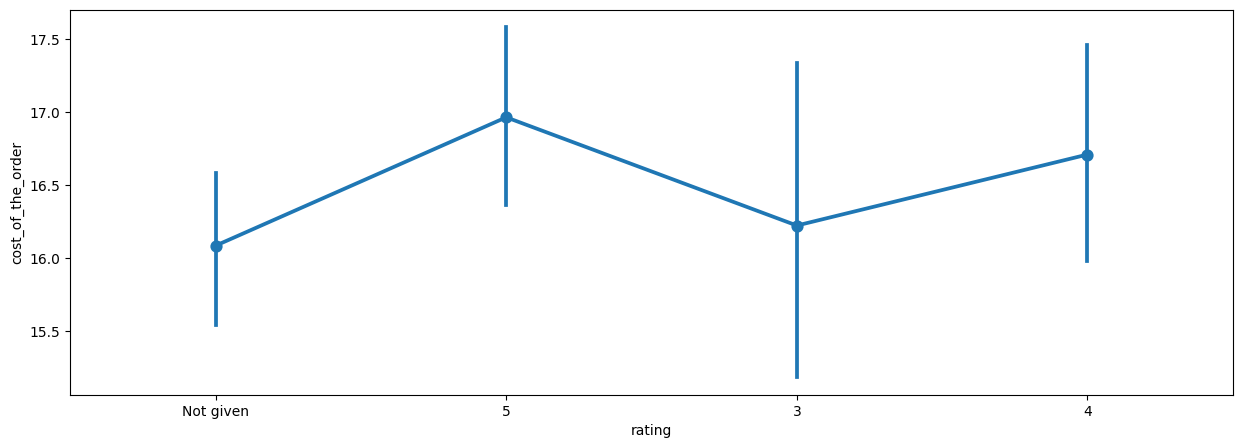

In [ ]:
# Relationship between rating and cost of the order
plt.figure(figsize=(15, 5))
sns.pointplot (x = "rating", y = "cost_of_the_order", data = df)
plt.show()

Correlation among variables

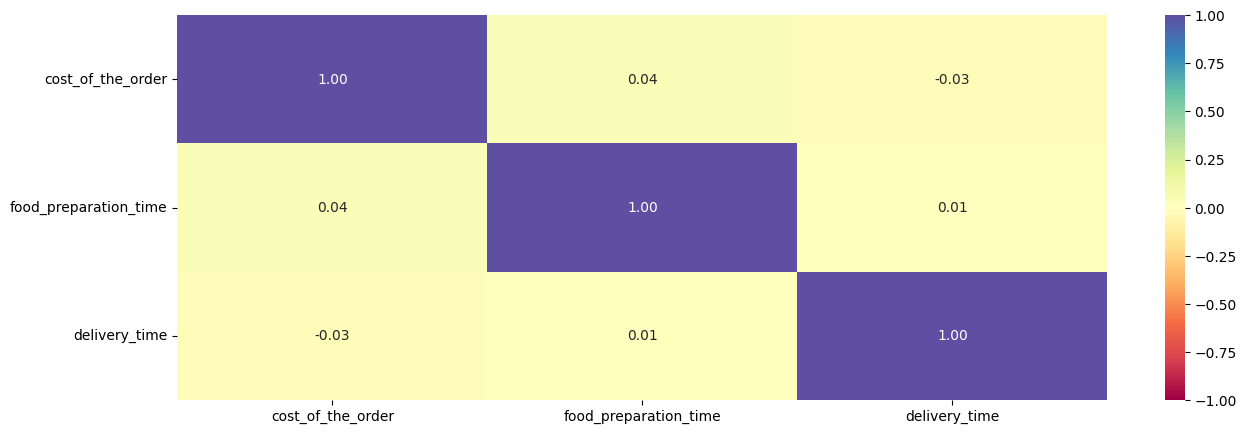

In [ ]:
# Plot the heatmap
col_list = ['cost_of_the_order', 'food_preparation_time', 'delivery_time']
plt.figure(figsize=(15, 5))
sns.heatmap(df[col_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

#### Observation: The multivariate analysis highlights important patterns in operational and customer-experience metrics. Cuisine type moderately affects order cost and food preparation time, indicating some variation across cuisines. Analysis of delivery times reveals that weekdays have longer durations than weekends, with a higher median (~28 minutes vs. ~22 minutes) and an overall upward-shifted distribution, suggesting factors like weekday traffic or staffing differences influence delivery speed more than order volume. Customer ratings show little dependence on delivery time, preparation time, or order cost, implying satisfaction is shaped by multiple experience factors. Revenue is primarily driven by higher order volumes rather than individual order prices, and correlation analysis confirms that operational variables—cost of the order, food preparation time, and delivery time—are largely independent. Overall, the results point to a multifactorial basis for customer satisfaction.

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [ ]:
# Filter the rated restaurants
df_rated = df[df['rating'] != 'Not given'].copy()

# Convert rating column from object to integer
df_rated['rating'] = df_rated['rating'].astype('int')

# Create a dataframe that contains the restaurant names with their rating counts
df_rating_count = df_rated.groupby(['restaurant_name'])['rating'].count().sort_values(ascending = False).reset_index()
df_rating_count.head()

,restaurant_name,rating
0,Shake Shack,133
1,The Meatball Shop,84
2,Blue Ribbon Sushi,73
3,Blue Ribbon Fried Chicken,64
4,RedFarm Broadway,41


In [ ]:
# Get the restaurant names that have rating count more than 50
restaurant_names = df_rating_count[df_rating_count['rating'] > 50]['restaurant_name']

# Filter to get the data of restaurants that have rating count more than 50
df_mean_4 = df_rated[df_rated['restaurant_name'].isin(restaurant_names)].copy()

# Group the restaurant names with their ratings and find the mean rating of each restaurant
df_mean_4_rating = df_mean_4.groupby(['restaurant_name'])['rating'].mean().sort_values(ascending = False).reset_index().dropna()

# filter for average rating greater than 4
df_avg_rating_greater_than_4 = df_mean_4_rating[df_mean_4_rating['rating'] > 4].sort_values(by='rating', ascending=False).reset_index(drop=True)

df_avg_rating_greater_than_4

,restaurant_name,rating
0,The Meatball Shop,4.511905
1,Blue Ribbon Fried Chicken,4.328125
2,Shake Shack,4.278195
3,Blue Ribbon Sushi,4.219178


#### Observations: From the analysis, only a few restaurants satisfy both promotional criteria (rating count > 50 and average rating > 4). The Meatball Shop has the highest average rating (4.51), indicating very strong customer satisfaction. Blue Ribbon Fried Chicken, Shake Shack, and Blue Ribbon Sushi also maintain strong average ratings (above 4) with substantial numbers of reviews.

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [ ]:
#function to determine the revenue
def compute_revenue(x):
    if x > 20:
        return x*0.25
    elif x > 5:
        return x*0.15
    else:
        return x*0

df['Revenue'] = df['cost_of_the_order'].apply(compute_revenue)
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time,rating_imputed,Revenue
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20,5.0,7.6875
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23,5.0,1.8120
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28,5.0,1.8345
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15,3.0,7.3000
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24,4.0,1.7385


In [ ]:
# get the total revenue
total_revenue = df['Revenue'].sum()
print('The net revenue is around', round(total_revenue, 2), 'dollars')

The net revenue is around 6166.3 dollars


#### Observation: The company generates revenue by charging a commission based on the order value. Orders costing more than 20 dollars contribute the highest revenue, as they are charged a higher commission rate of 25%, while orders costing greater than 5 dollars contribute revenue at a 15% commission rate. The total net revenue generated across all orders is 6166.3 dollars.

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [ ]:
# Calculate total delivery time and add a new column to the dataframe df to store the total delivery time
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

# Calculate percentage of orders with total delivery time greater than 60 minutes

percentage_over_60 = ((df['total_time'] > 60).sum() / df.shape[0]) * 100

print("Percentage of orders with total delivery time greater than 60 minutes:", round(percentage_over_60, 2), "%")

Percentage of orders with total delivery time greater than 60 minutes: 10.54 %


#### Observations: Approximately 10.54% of orders take more than 60 minutes to be delivered from the time the order is placed.


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [ ]:
# Get the mean delivery time on weekdays and print it
print('The mean delivery time on weekdays is around',
      round(df[df['day_of_the_week'] == 'Weekday']['delivery_time'].mean()),
     'minutes')


# Get the mean delivery time on weekends and print it
print('The mean delivery time on weekends is around',
      round(df[df['day_of_the_week'] == 'Weekend']['delivery_time'].mean()),
     'minutes')


The mean delivery time on weekdays is around 28 minutes
The mean delivery time on weekends is around 22 minutes


#### Observations: The average delivery time on weekdays (28 minutes) is significantly longer than on weekends (22 minutes). This suggests that weekday peak hour traffic has a measurable impact on logistics.


### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
The FoodHub order data analysis provides important insights into customer preferences, operational efficiency, and revenue generation patterns.

**(1) Cuisine Demand and Customer Preference:**

- American cuisine is the most popular cuisine during weekends, followed by Japanese and Italian cuisines, indicating strong customer demand for these food categories.

- Weekend ordering behavior shows higher engagement compared to weekdays, suggesting customers are more likely to order food during weekends.


**(2) Customer Feedback and Ratings:**

- A large number of orders initially had missing ratings (“Not given”), indicating that many customers do not actively provide feedback.

- After treating missing ratings using median imputation, most customer ratings were observed to be high (around 4–5), suggesting overall customer satisfaction with restaurant service and food quality.

**(3) Operational Efficiency:**

- The average food preparation time is approximately 27 minutes, and the average delivery time is about 24 minutes.

- Weekday delivery times (around 28 minutes) are longer compared to weekends (around 22 minutes), likely due to higher traffic congestion and operational challenges during working days.

- Approximately 10.54% of total orders take more than 60 minutes from preparation to delivery, which may negatively impact customer satisfaction.

**(4) Revenue Generation:**

- Orders costing more than $20 contribute significantly higher revenue because of the higher commission rate charged by the company.

- Increasing high-value orders can therefore directly improve company profitability.

**(5) Relationship Between Variables:**

- There is no strong linear relationship between cost of order, preparation time, and delivery time, indicating operational delays are likely influenced by external factors such as restaurant workload or traffic conditions.

### Recommendations:
Some suggestions that could help the company grow are listed below.

**(1) Focus on High-Demand Cuisines:**

- Partner more closely with high-performing American, Japanese, and Italian restaurants by offering promotions or prioritizing listing visibility during weekends.

- Expand partnerships with restaurants offering popular cuisines to capture higher order volumes.

**(2) Improve Customer Feedback Collection:**

- Encourage customers to submit ratings through incentives such as reward points or discount coupons.

- Improved feedback collection will help identify underperforming restaurants and enhance quality monitoring.

**(3) Reduce Delivery Delays:**

- Optimize delivery logistics during weekdays by improving driver allocation or using route optimization tools.

- Introduce dynamic delivery partner deployment during peak hours to reduce the percentage of orders exceeding 60 minutes.

**(4) Increase High-Value Orders:**

- Promote combo meals or bundled offers to increase average order value beyond $20, which generates higher commission revenue.

- Personalized recommendations based on customer ordering history may also encourage larger purchases.

**(5) Restaurant Performance Monitoring:**

- Monitor restaurants with longer preparation times and provide operational support or guidelines to improve efficiency.

- Highlight highly rated restaurants on the platform to maintain customer satisfaction and loyalty.

---